<a href="https://colab.research.google.com/github/SitiMutmainah15/PEMBELAJARAN-MESIN_GENAP_2026/blob/main/JS11/JS11_TUGASLAB.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

from tensorflow.keras import datasets, layers, models
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

tf.keras.utils.set_random_seed(42)

In [ ]:
print("GPU:", tf.config.list_physical_devices('GPU'))

GPU: []


In [ ]:
(train_images, train_labels), (test_images, test_labels) = datasets.cifar10.load_data()

print("Data training:", train_images.shape)
print("Data testing:", test_images.shape)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 550s 3us/step
Data training: (50000, 32, 32, 3)
Data testing: (10000, 32, 32, 3)


In [ ]:
train_images = train_images.astype('float32') / 255.0
test_images = test_images.astype('float32') / 255.0

train_labels = train_labels.ravel()
test_labels = test_labels.ravel()

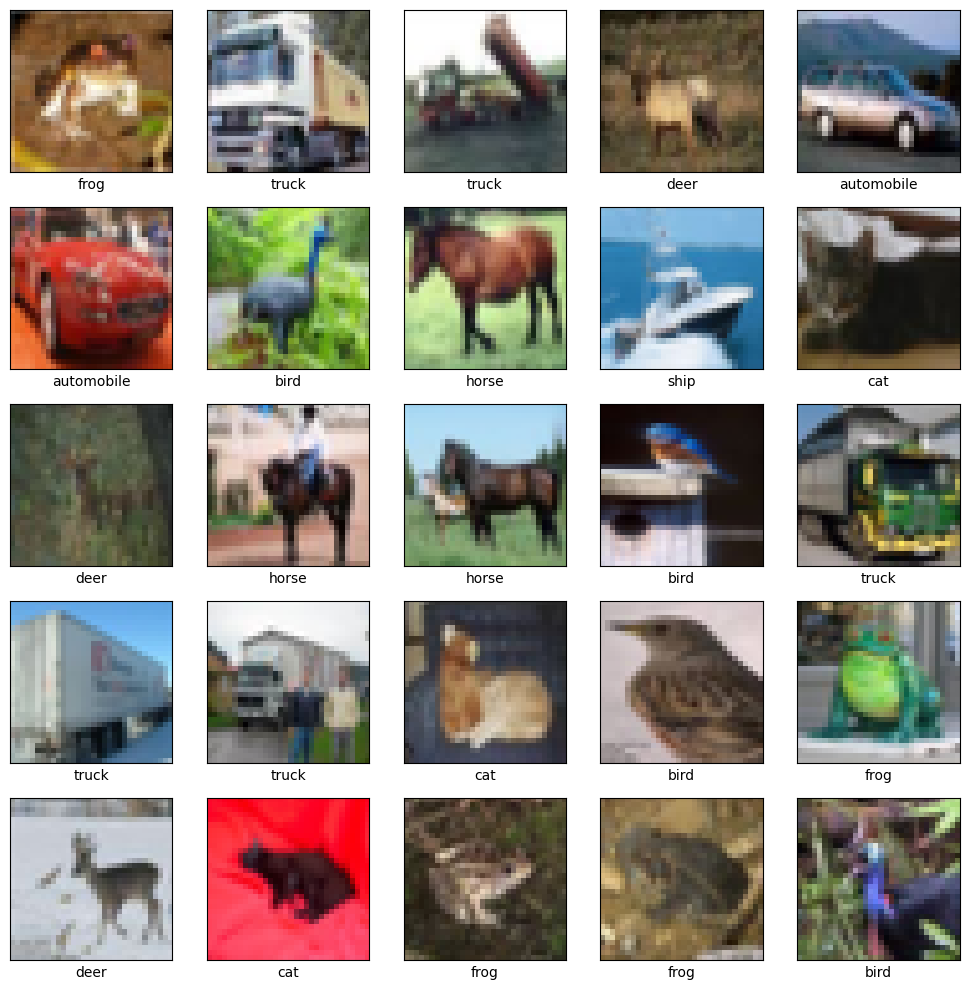

In [ ]:
class_names = [
    'airplane', 'automobile', 'bird', 'cat', 'deer',
    'dog', 'frog', 'horse', 'ship', 'truck'
]

plt.figure(figsize=(10, 10))

for i in range(25):
    plt.subplot(5, 5, i+1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(train_images[i])
    plt.xlabel(class_names[train_labels[i]])

plt.tight_layout()
plt.show()

In [ ]:
X_train, X_val, y_train, y_val = train_test_split(
    train_images,
    train_labels,
    test_size=0.1,
    random_state=42,
    stratify=train_labels
)

print("Data training:", X_train.shape)
print("Data validasi:", X_val.shape)
print("Data testing:", test_images.shape)

Data training: (45000, 32, 32, 3)
Data validasi: (5000, 32, 32, 3)
Data testing: (10000, 32, 32, 3)


In [ ]:
data_augmentation = models.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomTranslation(0.1, 0.1),
    layers.RandomZoom(0.1)
])

In [ ]:
model = models.Sequential([
    layers.Input(shape=(32, 32, 3)),
    data_augmentation,

    # Convolution Block 1
    layers.Conv2D(32, (3, 3), padding='same'),
    layers.BatchNormalization(),
    layers.Activation('relu'),

    layers.Conv2D(32, (3, 3), padding='same'),
    layers.BatchNormalization(),
    layers.Activation('relu'),

    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.2),

    # Convolution Block 2
    layers.Conv2D(64, (3, 3), padding='same'),
    layers.BatchNormalization(),
    layers.Activation('relu'),

    layers.Conv2D(64, (3, 3), padding='same'),
    layers.BatchNormalization(),
    layers.Activation('relu'),

    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.3),

    # Convolution Block 3
    layers.Conv2D(128, (3, 3), padding='same'),
    layers.BatchNormalization(),
    layers.Activation('relu'),

    layers.Conv2D(128, (3, 3), padding='same'),
    layers.BatchNormalization(),
    layers.Activation('relu'),

    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.4),

    # Fully Connected Layer
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.5),

    # Output Layer
    layers.Dense(10, activation='softmax')
])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 8, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │             

 Total params: 552,874 (2.11 MB)

 Trainable params: 551,722 (2.10 MB)

 Non-trainable params: 1,152 (4.50 KB)

In [ ]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [ ]:
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=15,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=4,
    min_lr=0.00001
)

In [11]:
history = model.fit(
    X_train,
    y_train,
    epochs=60,
    batch_size=64,
    validation_data=(X_val, y_val),
    callbacks=[early_stopping, reduce_lr]
)

Epoch 1/60
704/704 ━━━━━━━━━━━━━━━━━━━━ 453s 634ms/step - accuracy: 0.3579 - loss: 1.8343 - val_accuracy: 0.4860 - val_loss: 1.4125 - learning_rate: 0.0010
Epoch 2/60
704/704 ━━━━━━━━━━━━━━━━━━━━ 432s 613ms/step - accuracy: 0.4968 - loss: 1.3937 - val_accuracy: 0.5514 - val_loss: 1.3126 - learning_rate: 0.0010
Epoch 3/60
704/704 ━━━━━━━━━━━━━━━━━━━━ 441s 612ms/step - accuracy: 0.5639 - loss: 1.2247 - val_accuracy: 0.5730 - val_loss: 1.2209 - learning_rate: 0.0010
Epoch 4/60
704/704 ━━━━━━━━━━━━━━━━━━━━ 451s 625ms/step - accuracy: 0.6075 - loss: 1.1134 - val_accuracy: 0.5490 - val_loss: 1.3872 - learning_rate: 0.0010
Epoch 5/60
704/704 ━━━━━━━━━━━━━━━━━━━━ 432s 613ms/step - accuracy: 0.6375 - loss: 1.0347 - val_accuracy: 0.5534 - val_loss: 1.5239 - learning_rate: 0.0010
Epoch 6/60
704/704 ━━━━━━━━━━━━━━━━━━━━ 437s 606ms/step - accuracy: 0.6574 - loss: 0.9818 - val_accuracy: 0.6026 - val_loss: 1.2938 - learning_rate: 0.0010
Epoch 7/60
704/704 ━━━━━━━━━━━━━━━━━━━━ 424s 602ms/step - accura

KeyboardInterrupt: 

In [12]:
model.save('cifar10_modified_cnn.keras')

In [13]:
from google.colab import files

files.download('cifar10_modified_cnn.keras')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [14]:
test_loss, test_acc = model.evaluate(
    test_images,
    test_labels,
    verbose=2
)

print(f"Akurasi Testing: {test_acc * 100:.2f}%")
print(f"Testing Loss: {test_loss:.4f}")

if test_acc > 0.80:
    print("Target akurasi berhasil tercapai!")
else:
    print("Target akurasi belum tercapai.")

313/313 - 23s - 74ms/step - accuracy: 0.8238 - loss: 0.5431
Akurasi Testing: 82.38%
Testing Loss: 0.5431
Target akurasi berhasil tercapai!


In [15]:
print(f"Akurasi Testing: {test_acc * 100:.2f}%")
print(f"Testing Loss: {test_loss:.4f}")

if test_acc > 0.80:
    print("Target akurasi lebih dari 80% berhasil tercapai!")
else:
    print("Target akurasi belum tercapai.")

Akurasi Testing: 82.38%
Testing Loss: 0.5431
Target akurasi lebih dari 80% berhasil tercapai!


In [16]:
model.save('cifar10_modified_cnn.keras')

In [ ]:
jumlah_benar = np.sum(y_pred == test_labels)
jumlah_salah = np.sum(y_pred != test_labels)

print("Total data testing:", len(test_labels))
print("Prediksi benar:", jumlah_benar)
print("Prediksi salah:", jumlah_salah)
print(f"Akurasi: {test_acc * 100:.2f}%")

TUGAS 2

In [17]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

from tensorflow.keras import datasets, layers, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

tf.keras.utils.set_random_seed(42)

In [18]:
(train_images, train_labels), (test_images, test_labels) = datasets.mnist.load_data()

print("Data training:", train_images.shape)
print("Data testing:", test_images.shape)
print("Label training:", train_labels.shape)
print("Label testing:", test_labels.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Data training: (60000, 28, 28)
Data testing: (10000, 28, 28)
Label training: (60000,)
Label testing: (10000,)


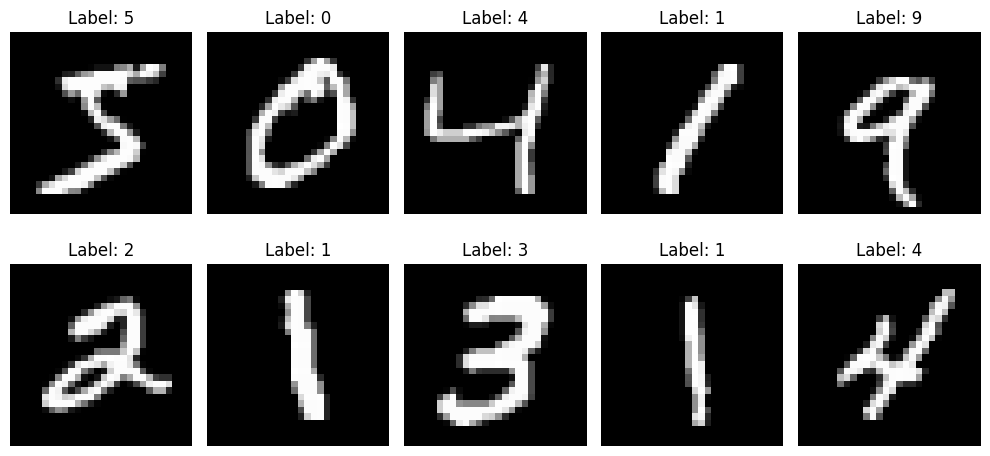

In [19]:
plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i+1)
    plt.imshow(train_images[i], cmap='gray')
    plt.title(f"Label: {train_labels[i]}")
    plt.axis('off')

plt.tight_layout()
plt.show()

In [20]:
train_images = train_images.astype('float32') / 255.0
test_images = test_images.astype('float32') / 255.0

In [21]:
train_images = train_images.reshape(-1, 28, 28, 1)
test_images = test_images.reshape(-1, 28, 28, 1)

print("Training:", train_images.shape)
print("Testing:", test_images.shape)

Training: (60000, 28, 28, 1)
Testing: (10000, 28, 28, 1)


In [22]:
X_train, X_val, y_train, y_val = train_test_split(
    train_images,
    train_labels,
    test_size=0.1,
    random_state=42,
    stratify=train_labels
)

print("Data training:", X_train.shape)
print("Data validasi:", X_val.shape)
print("Data testing:", test_images.shape)

Data training: (54000, 28, 28, 1)
Data validasi: (6000, 28, 28, 1)
Data testing: (10000, 28, 28, 1)


In [23]:
model = models.Sequential([
    layers.Input(shape=(28, 28, 1)),

    # Convolution Layer 1
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Convolution Layer 2
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Fully Connected Layer
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),

    # Output Layer
    layers.Dense(10, activation='softmax')
])

model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [24]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [25]:
history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=128,
    validation_data=(X_val, y_val)
)

Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 62s 145ms/step - accuracy: 0.9251 - loss: 0.2493 - val_accuracy: 0.9773 - val_loss: 0.0824
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 44s 105ms/step - accuracy: 0.9766 - loss: 0.0762 - val_accuracy: 0.9852 - val_loss: 0.0547
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 47s 111ms/step - accuracy: 0.9833 - loss: 0.0552 - val_accuracy: 0.9865 - val_loss: 0.0498
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 44s 104ms/step - accuracy: 0.9869 - loss: 0.0428 - val_accuracy: 0.9870 - val_loss: 0.0484
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 82s 104ms/step - accuracy: 0.9898 - loss: 0.0341 - val_accuracy: 0.9892 - val_loss: 0.0443
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 82s 104ms/step - accuracy: 0.9905 - loss: 0.0303 - val_accuracy: 0.9895 - val_loss: 0.0440
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 83s 108ms/step - accuracy: 0.9919 - loss: 0.0250 - val_accuracy: 0.9892 - val_loss: 0.0433
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 44s 105ms/step - accuracy: 0.9935 - loss: 0

In [26]:
test_loss, test_acc = model.evaluate(
    test_images,
    test_labels,
    verbose=2
)

print(f"Akurasi Testing: {test_acc * 100:.2f}%")
print(f"Testing Loss: {test_loss:.4f}")

313/313 - 4s - 14ms/step - accuracy: 0.9913 - loss: 0.0292
Akurasi Testing: 99.13%
Testing Loss: 0.0292


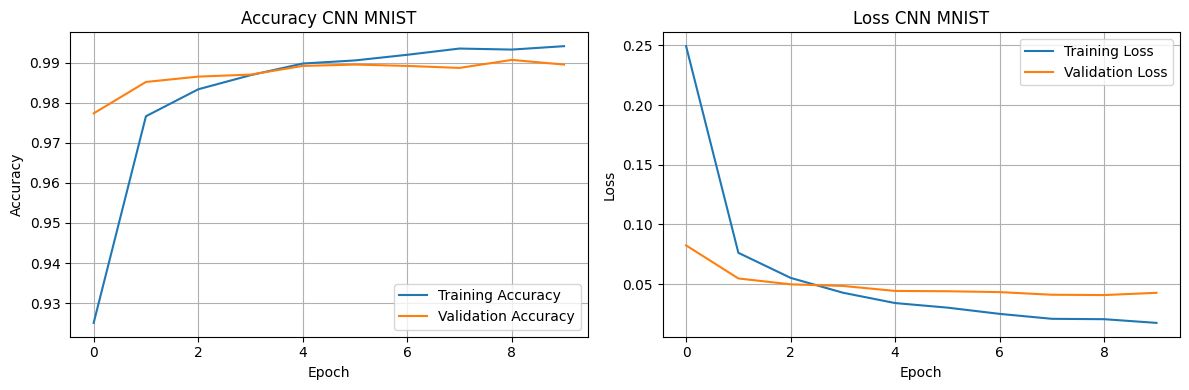

In [27]:
plt.figure(figsize=(12, 4))

# Grafik Accuracy
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Accuracy CNN MNIST')
plt.legend()
plt.grid()

# Grafik Loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Loss CNN MNIST')
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

In [28]:
y_pred_prob = model.predict(test_images)
y_pred = np.argmax(y_pred_prob, axis=1)

print("Label sebenarnya:", test_labels[:10])
print("Hasil prediksi  :", y_pred[:10])

313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step
Label sebenarnya: [7 2 1 0 4 1 4 9 5 9]
Hasil prediksi  : [7 2 1 0 4 1 4 9 5 9]


In [29]:
print(classification_report(
    test_labels,
    y_pred,
    digits=4
))

              precision    recall  f1-score   support

           0     0.9919    0.9959    0.9939       980
           1     0.9956    0.9982    0.9969      1135
           2     0.9932    0.9884    0.9908      1032
           3     0.9940    0.9861    0.9901      1010
           4     0.9979    0.9908    0.9944       982
           5     0.9802    0.9978    0.9889       892
           6     0.9968    0.9875    0.9921       958
           7     0.9855    0.9893    0.9874      1028
           8     0.9877    0.9928    0.9903       974
           9     0.9891    0.9861    0.9876      1009

    accuracy                         0.9913     10000
   macro avg     0.9912    0.9913    0.9912     10000
weighted avg     0.9913    0.9913    0.9913     10000



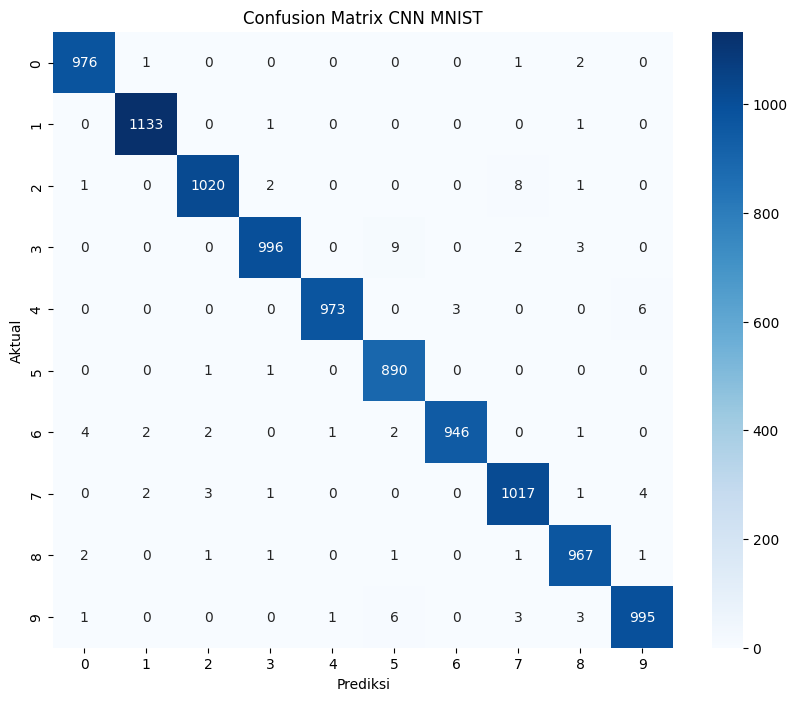

In [30]:
cm = confusion_matrix(test_labels, y_pred)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=range(10),
    yticklabels=range(10)
)

plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.title('Confusion Matrix CNN MNIST')
plt.show()

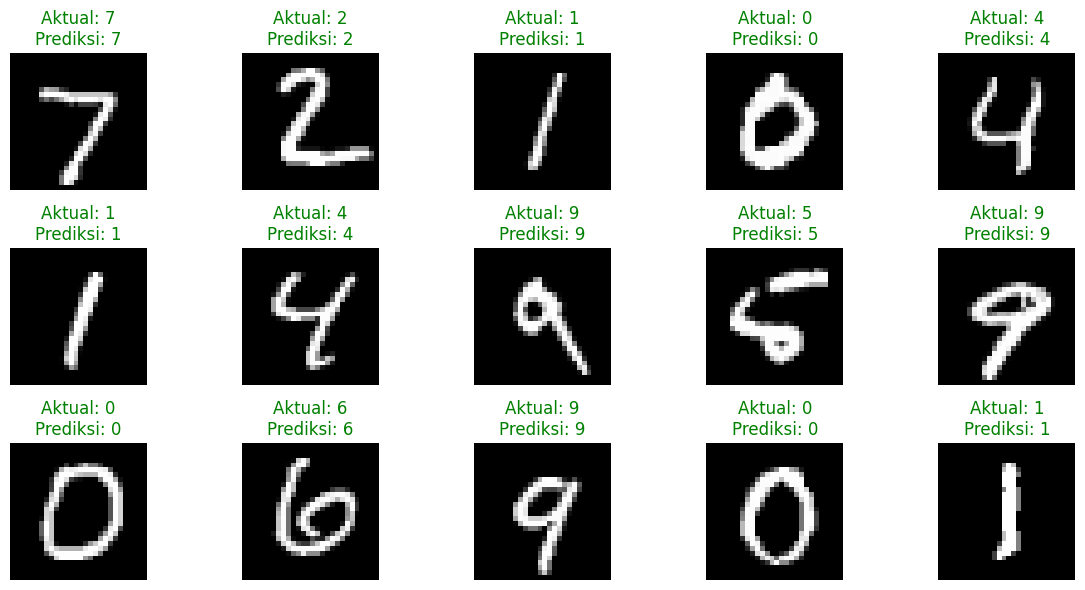

In [31]:
plt.figure(figsize=(12, 6))

for i in range(15):
    plt.subplot(3, 5, i+1)

    plt.imshow(
        test_images[i].reshape(28, 28),
        cmap='gray'
    )

    warna = 'green' if y_pred[i] == test_labels[i] else 'red'

    plt.title(
        f"Aktual: {test_labels[i]}\n"
        f"Prediksi: {y_pred[i]}",
        color=warna
    )

    plt.axis('off')

plt.tight_layout()
plt.show()

In [32]:
jumlah_benar = np.sum(y_pred == test_labels)
jumlah_salah = np.sum(y_pred != test_labels)

print("Total data testing:", len(test_labels))
print("Prediksi benar:", jumlah_benar)
print("Prediksi salah:", jumlah_salah)
print(f"Akurasi: {test_acc * 100:.2f}%")

Total data testing: 10000
Prediksi benar: 9913
Prediksi salah: 87
Akurasi: 99.13%


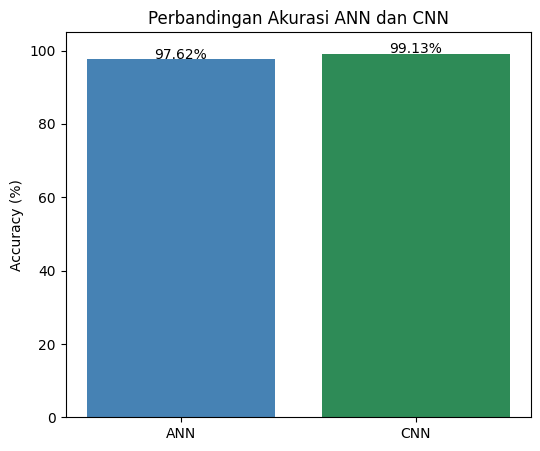

Akurasi ANN: 97.62%
Akurasi CNN: 99.13%
Selisih: 1.51 poin persentase


In [33]:
ann_accuracy = 97.62
cnn_accuracy = test_acc * 100

plt.figure(figsize=(6, 5))

bars = plt.bar(
    ['ANN', 'CNN'],
    [ann_accuracy, cnn_accuracy],
    color=['steelblue', 'seagreen']
)

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 0.2,
        f'{bar.get_height():.2f}%',
        ha='center'
    )

plt.ylim(0, 105)
plt.ylabel('Accuracy (%)')
plt.title('Perbandingan Akurasi ANN dan CNN')
plt.show()

print(f"Akurasi ANN: {ann_accuracy:.2f}%")
print(f"Akurasi CNN: {cnn_accuracy:.2f}%")
print(f"Selisih: {cnn_accuracy - ann_accuracy:.2f} poin persentase")